# 02 — Tree search vs integrated search in DHT

The paper (§4.2, p.443) defines **two ways** to search the per-sample architecture space:

- **Tree search (T-DHT)** decides *hierarchically*: first how deep, then at every 3-layer group how
  many heads, then which heads.
- **Integrated search (S-DHT / F-DHT)** decides depth *and* head count *jointly, once*, then only
  which heads at each group.

This notebook explains both, shows exactly where the code differs, and compares them on AG News:

- **T-DHT:** our completed seed-7 run.
- **F-DHT** (the paper's "Full DHT" integrated configuration): trained for this notebook with the
  same seed, data, optimizer and budget (decision D016).
- **Fixed 12-layer BERT:** the no-DHT reference.

The last section measures **wall-clock speed**, including the batched execution engine (D017) that
turns DHT's FLOP savings into real time savings.

> **TL;DR (AG News, seed 7, matched protocol).**
>
> - **Accuracy.** Integrated search (F-DHT) reached test macro F1 **.9409**, tree search (T-DHT)
>   **.9400**, fixed BERT **.9490**. The two DHT modes are statistically indistinguishable on one seed
>   (F-DHT wins 86 samples, T-DHT wins 79).
> - **Compute.** F-DHT uses a little *more* task compute (0.43x vs 0.39x FLOPs) and spends it
>   differently. It sends **63% of samples to a moderate 6-layer path** (mostly with 8 heads), while
>   T-DHT sends 63% to the 3-layer exit and a minority deep.
> - **Speed.** With the batched engine plus GPU context pooling, T-DHT **trains 1.60× faster than
>   fixed BERT** (was 0.59×). **Both modes infer ~1.1× faster than fixed BERT** on the GPU at batch 32
>   (were 0.20–0.26×). Every routing decision on all 6,000 validation samples is unchanged.

In [1]:
import difflib
import inspect
import json
import subprocess
from collections import Counter

import matplotlib.pyplot as plt
import nb_utils as u
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from dht.policies.controller import DHTController

u.style()
MODELS = ["Fixed BERT", "T-DHT", "F-DHT"]
assert all(m in u.available_models() for m in MODELS), u.available_models()
print("runs:", {m: u.EXPORTS[m] for m in MODELS})

runs: {'Fixed BERT': 'ag-news-fixed-full-seed7', 'T-DHT': 'ag-news-tree-full-seed7-resume-d015', 'F-DHT': 'ag-news-fdht-full-seed7'}


## 1. The two search modes, conceptually

Both modes share the same skeleton (Algorithm 2 p.444, Fig. 1 p.445):

1. The first **b = 3 layers are always full** (12 heads). Their output is the *context* for every
   decision.
2. **Stage 1 (routing):** the sample passes the prefix *without gradients*, a UCB bandit picks an
   action, and the sample waits in the **queue** for its depth.
3. **Stage 2 (training):** when the queue is full, the batch *re-runs* the prefix with gradients,
   then executes the remaining **c = 3-layer groups** according to the decisions, and the model is
   updated.
4. The bandits get **rewards** built from loss × cost relative to the previous batch.

They differ in **what is decided where**:

```
TREE SEARCH (T-DHT)                                  INTEGRATED SEARCH (F-DHT / S-DHT)
────────────────────                                 ─────────────────────────────────
prefix(3 layers) ──► UCB_L: depth L ∈ {3,6,9,12}     prefix(3 layers) ──► UCB_cp: pair (L,H) ∈ list
                     │                                                     │    e.g. (6,8), (9,12), (3,12)…
      ┌──────────────┘                                     ┌───────────────┘
      ▼   for each 3-layer group g < L:                    ▼   for each 3-layer group g < L:
  UCB_H(context_g, group one-hot): H_g ∈ {8,10,12}     H is FIXED (from the pair)
  TSB(context_g): which H_g heads                      TSB(context_g): which H heads
      │                                                    │
      ▼                                                    ▼
 rewards: r_L  ∝ 1/(loss·L)          → UCB_L          reward: r_cp ∝ 1/(loss·L·H) → UCB_cp
          r_H,g ∝ 1/(loss·H_g)        → UCB_H at g           TS label from r_cp
          TS label from r_H,g
```

| | Tree search | Integrated search |
|---|---|---|
| Paper | §4.2.1, Alg. 2 | §4.2.2 |
| Bandits | UCB_L (depth) + UCB_H (count, shared across groups) + TSB | UCB_cp (pair) + TSB |
| Decisions per sample | 1 depth + (#groups × count) + (#groups × subset) | 1 pair + (#groups × subset) |
| Head count across groups | **can change** per group (e.g. 8 → 12 → 10) | **constant** |
| Count decision sees | the *current* group's representation (deeper = more informed) | only the layer-3 representation |
| Can exclude combinations | no (full product) | **yes** — the pair list is curated (S-DHT forbids pruning heads unless L = 12) |
| Reward cost term | depth and heads rewarded **separately** | one joint cost loss·L·H |
| Exploration | 3 bandits explore jointly | one bandit over a flat list |

**Intuition.** Tree search is more *adaptive*: it can decide "go deep, but thin" and change head
count as evidence accumulates. It also has more interacting learners and noisier credit assignment.
Integrated search is a *flat* bandit over a curated menu. It is simpler, has one reward signal, and
lets the designer rule out bad combinations, but it must commit to the head count from the layer-3
context alone.

In [2]:
# How big is each action space? (count patterns; identities multiply these further)
from math import comb

tree_depths, counts, groups = [3, 6, 9, 12], [8, 10, 12], 3
tree_patterns = sum(len(counts) ** ((d - 3) // 3) for d in tree_depths)
fdht_pairs = [
    (3, 12),
    (6, 8),
    (6, 10),
    (6, 12),
    (9, 8),
    (9, 10),
    (9, 12),
    (12, 8),
    (12, 10),
    (12, 12),
]
sdht_pairs = [(3, 12), (6, 12), (9, 12), (12, 8), (12, 10), (12, 12)]
ids = {c: comb(12, c) for c in counts}
tree_full = sum(sum(ids[c] for c in counts) ** ((d - 3) // 3) for d in tree_depths)
fdht_full = sum(ids.get(h, 1) ** ((L - 3) // 3) if L > 3 else 1 for L, h in fdht_pairs)
pd.DataFrame(
    {
        "top-level UCB arms": [len(tree_depths), len(fdht_pairs), len(sdht_pairs)],
        "distinct (depth, per-group count) patterns": [
            tree_patterns,
            len(fdht_pairs),
            len(sdht_pairs),
        ],
        "incl. head identities (unrestricted TS)": [f"{tree_full:.2e}", f"{fdht_full:.2e}", "—"],
    },
    index=["T-DHT (tree)", "F-DHT (integrated)", "S-DHT (integrated)"],
)

,top-level UCB arms,"distinct (depth, per-group count) patterns",incl. head identities (unrestricted TS)
T-DHT (tree),4,40,1.78e+08
F-DHT (integrated),10,10,1.22e+08
S-DHT (integrated),6,6,—


Tree search reaches **40** depth/count patterns, while F-DHT reaches its **10** listed pairs. F-DHT
is equivalent to a tree search whose head count is forced to be the same in every group. (§6.1
states "70, 28, 1 head combinations" for 8/10/12 heads without explaining the restriction. Our TS
may pick any subset; see `docs/reproduction/ambiguities.md`.)

## 2. What actually differs in the code

Both modes live in one class, `DHTController` (`src/dht/policies/controller.py`), which switches on
`options.mode`. Below, every line that depends on the mode is **marked with ◀** so you can read the
two branches in context.

In [3]:
def show_mode_lines(function, context=2):
    source, start = inspect.getsourcelines(function)
    import re

    pattern = re.compile(r'options\.mode|route_key|route\.head_count|"pair"')
    hits = [i for i, line in enumerate(source) if pattern.search(line)]
    keep = sorted(
        {j for i in hits for j in range(max(0, i - context), min(len(source), i + context + 1))}
    )
    print(f"── {function.__qualname__}  (controller.py:{start})")
    last = None
    for j in keep:
        if last is not None and j != last + 1:
            print("   ⋮")
        mark = "◀" if j in hits else " "
        print(f"{start + j:4d} {mark} {source[j].rstrip()}")
        last = j
    print()


for fn in [
    DHTController.__init__,
    DHTController.route,
    DHTController.execute,
    DHTController.update,
]:
    show_mode_lines(fn)

── DHTController.__init__  (controller.py:65)
  71           raw_head = features.head_arms.shape[-1]
  72           raw_ts = features.ts_arms.shape[-1]
  73 ◀         route_count = len(self.depths) if self.options.mode == "tree" else len(self.pairs)
  74           self.route_ucb = LinearUCB(
  75               route_count, 2 * raw_depth, config.bandit.ucb_ridge, config.bandit.ucb_exploration
   ⋮
  82                   config.bandit.ucb_exploration,
  83               )
  84 ◀             if self.options.mode == "tree" and features.groups
  85               else None
  86           )

── DHTController.route  (controller.py:99)
 127           try:
 128               hidden, mask = model.prefix(tokens)
 129 ◀             kind = "depth" if self.options.mode == "tree" else "pair"
 130               w = self.features.aggregate(hidden, mask, kind)
 131               if trace is not None:

── DHTController.execute  (controller.py:141)
 174                   break
 175               count_arm,

The four places where the modes diverge:

1. **`__init__` — which bandits exist.** Tree builds `route_ucb` over *depths* **and** a `head_ucb`
   over counts; its feature width adds a one-hot for the group. Integrated builds `route_ucb` over
   *pairs* and no `head_ucb`. Both share one TS over 12 heads.
2. **`route` — what stage 1 chooses.** The same pooled layer-3 context is concatenated with
   depth-arm descriptors (tree) or pair-arm descriptors (integrated). The pair descriptor is the
   average representation after *L layers with H heads*, built during calibration.
3. **`execute` — who picks the head count.** Tree: `head_ucb.select(...)` on the *current* group's
   representation. Integrated: `count = route.head_count` (fixed for all groups). TS then picks
   identities identically in both.
4. **`update` — rewards.** Tree computes a depth product (loss·L) for UCB_L and one head product per
   group (loss·H_g) for UCB_H and TS. Integrated computes one product loss·L·H, whose ratio updates
   UCB_cp *and* provides the TS label for every group.

The experiment configs differ in exactly three lines:

In [4]:
tree = (u.ROOT / "configs/experiment/ag_news_tree_full.toml").read_text().splitlines()
fdht = (u.ROOT / "configs/experiment/ag_news_fdht_full.toml").read_text().splitlines()
print(
    "\n".join(
        line
        for line in difflib.unified_diff(
            tree, fdht, "ag_news_tree_full.toml", "ag_news_fdht_full.toml", lineterm="", n=0
        )
    )
)

--- ag_news_tree_full.toml
+++ ag_news_fdht_full.toml
@@ -1,3 +1,4 @@
-# D013: FULL-DATA planned run; do not launch without runtime approval.
-# Keep the primary reproduction feedback literal. The alternative is a named diagnostic.
-name = "ag_news_tree_full"
+# D016: FULL-DATA F-DHT (integrated search, §4.2.2 p.443; F-DHT list §6.1 p.446).
+# Identical to ag_news_tree_full.toml except name, mode and the explicit UCB_cp pair
+# list, so fixed/T-DHT/F-DHT form a matched seed-7 comparison. Approved 2026-09-22.
+name = "ag_news_fdht_full"
@@ -47 +48,4 @@
-mode = "tree"
+mode = "integrated"
+# Paper F-DHT UCB_cp options: 3L12H, 6L8H, 6L10H, 6L12H, 9L8H, 9L10H, 9L12H,
+# 12L8H, 12L10H, 12L12H. Depth is TOTAL depth (D001); 3 = full-head prefix only.
+pairs = [[3, 12], [6, 8], [6, 10], [6, 12], [9, 8], [9, 10], [9, 12], [12, 8], [12, 10], [12, 12]]


### Is the integrated implementation right? — the tests

Integrated search was implemented earlier alongside tree search. For this comparison it gained a
real-data configuration, a decision-trace API (`explain`) and the batched engine. The tests below
cover:

- exact checkpoint/resume
- that `explain` reproduces frozen predictions
- that batched execution is decision-identical to per-sample execution

Each runs for both modes.

In [5]:
result = subprocess.run(
    [
        "uv",
        "run",
        "pytest",
        "-q",
        "-k",
        "integrated or batched or explain",
        "tests/integration/test_dht.py",
        "tests/integration/test_batched_dht.py",
        "tests/integration/test_prefix_passes.py",
        "--color=no",
        "-p",
        "no:cacheprovider",
    ],
    cwd=u.ROOT,
    capture_output=True,
    text=True,
)
print(result.stdout.strip().splitlines()[-1])

23 passed, 9 deselected in 2.85s


## 3. What each learned policy looks like after training

Pull counts show how often each top-level arm was *played* (and therefore updated) during the three
training epochs.

,route arms,route feature width,count-UCB,TS,route pulls,TS head updates,reward ratios capped
T-DHT,4,168,3 arms × 87,12 heads × 24,341992,2115158,81574
F-DHT,10,168,—,12 heads × 24,227992,1573044,31474


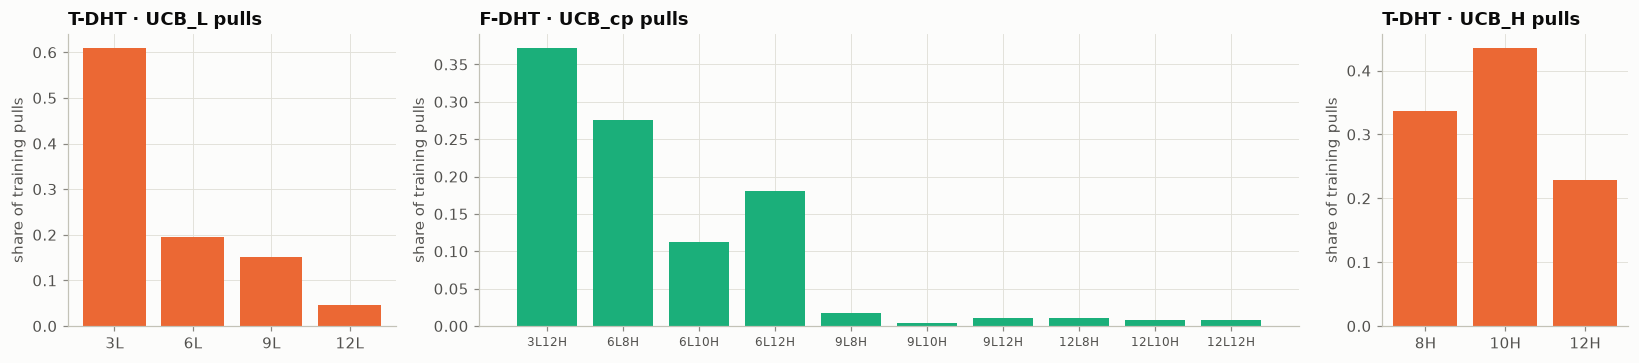

In [6]:
from dht.config import ExperimentConfig
from dht.training.checkpointing import read_checkpoint

states = {m: read_checkpoint(u.RUNS / u.EXPORTS[m] / "best.pt") for m in ["T-DHT", "F-DHT"]}
ctl = {m: s["training_state"]["controller"] for m, s in states.items()}
cfgs = {m: ExperimentConfig.model_validate(s["config"]) for m, s in states.items()}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), gridspec_kw={"width_ratios": [4, 10, 3]})
d, c, p = cfgs["T-DHT"].dht.actions(cfgs["T-DHT"].model)
n = ctl["T-DHT"]["route_ucb"]["counts"].numpy()
axes[0].bar([f"{x}L" for x in d], n / n.sum(), color=u.MODEL_COLORS["T-DHT"])
axes[0].set_title("T-DHT · UCB_L pulls")
d2, c2, p2 = cfgs["F-DHT"].dht.actions(cfgs["F-DHT"].model)
n2 = ctl["F-DHT"]["route_ucb"]["counts"].numpy()
axes[1].bar([f"{L}L{H}H" for L, H in p2], n2 / n2.sum(), color=u.MODEL_COLORS["F-DHT"])
axes[1].set_title("F-DHT · UCB_cp pulls")
axes[1].tick_params(axis="x", labelsize=8)
nh = ctl["T-DHT"]["head_ucb"]["counts"].numpy()
axes[2].bar([f"{x}H" for x in c], nh / nh.sum(), color=u.MODEL_COLORS["T-DHT"])
axes[2].set_title("T-DHT · UCB_H pulls")
for ax in axes:
    ax.set_ylabel("share of training pulls")
fig.tight_layout()
shapes = pd.DataFrame(
    {
        m: {
            "route arms": ctl[m]["route_ucb"]["shape"][0],
            "route feature width": ctl[m]["route_ucb"]["shape"][1],
            "count-UCB": "—"
            if ctl[m]["head_ucb"] is None
            else f"{ctl[m]['head_ucb']['shape'][0]} arms × {ctl[m]['head_ucb']['shape'][1]}",
            "TS": f"{ctl[m]['ts']['shape'][0]} heads × {ctl[m]['ts']['shape'][1]}",
            "route pulls": int(ctl[m]["route_ucb"]["counts"].sum()),
            "TS head updates": int(ctl[m]["ts"]["counts"].sum()),
            "reward ratios capped": ctl[m]["rewards"]["clipped"],
        }
        for m in ctl
    }
).T
shapes

Two details are worth noticing:

- The route-UCB feature width is **168** and tree's count-UCB width is **87**, exactly the vector
  sizes the paper reports in §7.3. They come from our pooling bins: 2 × 84 for depth/pair, and
  2 × 42 + 3 group markers for counts. This independently supports that reconstruction.
- Both modes update Thompson sampling heavily: 2.1M head updates for T-DHT (all 3 epochs) and 1.6M
  for F-DHT (its selected epoch-2 checkpoint). F-DHT's single joint reward was capped about as often
  per update: 31,474 capped ratios at epoch 2 (57,579 over the full run) vs 81,574 for T-DHT.
- F-DHT's pull counts show that its pair UCB ended up concentrated on 3L12H and the three 6-layer
  pairs. Deep pairs are rarely played.

## 4. Final results

In [7]:
paper = pd.read_csv(u.ROOT / "references/paper_results.csv").query("dataset == 'ag_news'")
paper_key = {"Fixed BERT": "12-VaBERT", "T-DHT": "T-DHT", "F-DHT": "F-DHT"}
preds = {m: u.load_predictions(m) for m in MODELS}
raw_test = u.load_dataset("AG News", "test")
for m, f in preds.items():
    f["text"] = raw_test.text.values[f.source_index]
    f["flops"] = [u.relative_matmul_flops(d, c) for d, c in zip(f.total_depth, f.group_counts)]
rows = []
for m in MODELS:
    export = json.loads((u.ANALYSIS / f"{u.EXPORTS[m]}.test.summary.json").read_text())
    summ = u.run_summary(m)
    test_arch = u.run_json(m, "final_test.json")["metrics"].get("architectures", {})
    pr = paper.set_index(["cost_phase", "model"])
    rows.append(
        {
            "model": m,
            "val macro F1": summ["best_validation_score"],
            "test macro F1": export["metrics"]["macro_f1"],
            "test accuracy": export["metrics"]["accuracy"],
            "export = recorded": export["matches_recorded"],
            "paper F1": pr.loc[("inference", paper_key[m]), "f1"],
            "task FLOPs (test)": preds[m].flops.mean(),
            "+ routing prefix": preds[m].flops.mean()
            + (u.relative_matmul_flops(3, ()) if m != "Fixed BERT" else 0),
            "paper infer. FLOPs": pr.loc[("inference", paper_key[m]), "flop_ratio"],
            "paper train FLOPs": pr.loc[("training", paper_key[m]), "flop_ratio"],
            "mean depth (test)": preds[m].total_depth.mean(),
            "train step time (h)": summ.get("cumulative_training_step_seconds", np.nan) / 3600,
        }
    )
final = pd.DataFrame(rows).set_index("model")
final.style.format(
    {
        "val macro F1": "{:.4f}",
        "test macro F1": "{:.4f}",
        "test accuracy": "{:.4f}",
        "paper F1": "{:.3f}",
        "task FLOPs (test)": "{:.3f}x",
        "+ routing prefix": "{:.3f}x",
        "paper infer. FLOPs": "{:.2f}x",
        "paper train FLOPs": "{:.2f}x",
        "mean depth (test)": "{:.2f}",
        "train step time (h)": "{:.2f}",
    }
)

,val macro F1,test macro F1,test accuracy,export = recorded,paper F1,task FLOPs (test),+ routing prefix,paper infer. FLOPs,paper train FLOPs,mean depth (test),train step time (h)
model,,,,,,,,,,,
Fixed BERT,0.9480,0.9490,0.9491,True,0.944,1.000x,1.000x,1.00x,1.00x,12.00,1.88
T-DHT,0.9438,0.9400,0.9400,True,0.945,0.386x,0.636x,0.81x,0.42x,4.75,2.96
F-DHT,0.9452,0.9409,0.9409,True,0.943,0.432x,0.682x,0.35x,0.59x,5.35,3.72


**Reading the results table.**

- **Accuracy.** Both DHT modes lose about 0.8–0.9 points of test macro F1 against our fixed baseline.
  F-DHT is 0.0009 ahead of T-DHT on test (7 samples out of 7,600) and 0.0014 ahead on validation.
  With one seed that is **a tie**, not a ranking. Note that F-DHT's best checkpoint is from
  **epoch 2**; its epoch-3 validation fell to .9401, so the validation protocol kept epoch 2.
- **Paper comparison.** The paper reports T-DHT .945 and F-DHT .943 against BERT .944; we measure
  .940 and .941 against a stronger .949 baseline. The paper's *ordering* of compute is **not**
  reproduced: it reports F-DHT inference at 0.35x and T-DHT at 0.81x, while ours are 0.43x and 0.39x.
- **Training time** in this table is the per-sample implementation both runs used (D016 keeps them
  comparable). F-DHT took 3.7 h vs T-DHT's 3.0 h because it runs more 6-layer paths. Section 9 shows
  the batched engine.

Next, the accuracy–compute picture next to the paper's reported points. Our points are *measured*
test F1 against estimated task FLOPs. The paper's are *reported* values. Both use a
FLOP ratio relative to 12-layer BERT, but the paper does not define its FLOP scope precisely.

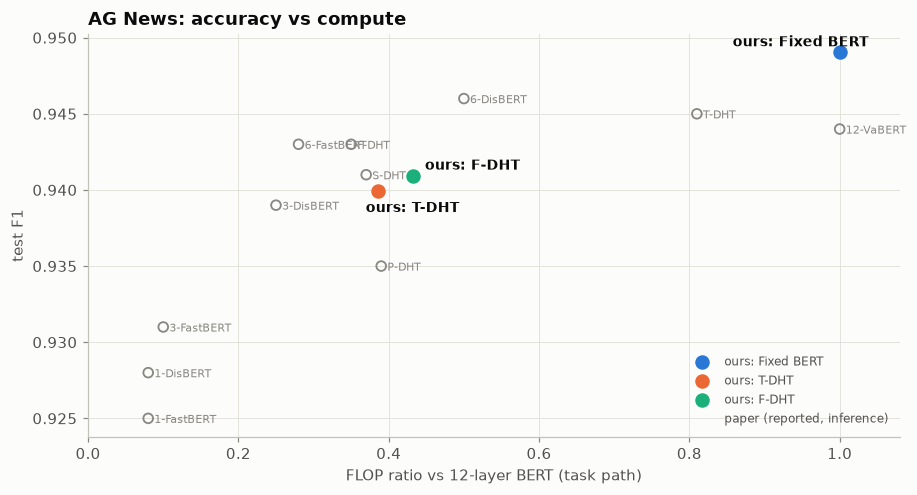

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
inf = paper[paper.cost_phase == "inference"]
for _, r in inf.iterrows():
    ax.scatter(r.flop_ratio, r.f1, s=40, facecolor="none", edgecolor=u.MUTED, lw=1.2, zorder=2)
    ax.annotate(
        r.model,
        (r.flop_ratio, r.f1),
        xytext=(4, -3),
        textcoords="offset points",
        fontsize=7,
        color=u.MUTED,
    )
for m in MODELS:
    ax.scatter(
        final.loc[m, "task FLOPs (test)"],
        final.loc[m, "test macro F1"],
        s=90,
        color=u.MODEL_COLORS[m],
        zorder=3,
        label=f"ours: {m}",
    )
    offset = {"T-DHT": (-8, -14), "F-DHT": (8, 4), "Fixed BERT": (-70, 4)}[m]
    ax.annotate(
        f"ours: {m}",
        (final.loc[m, "task FLOPs (test)"], final.loc[m, "test macro F1"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=9,
        color=u.INK,
        weight="bold",
    )
ax.scatter([], [], s=40, facecolor="none", edgecolor=u.MUTED, label="paper (reported, inference)")
ax.set_xlabel("FLOP ratio vs 12-layer BERT (task path)")
ax.set_ylabel("test F1")
ax.set_xlim(0, 1.08)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("AG News: accuracy vs compute")
fig.tight_layout()

## 5. How the two policies spend compute on the test set

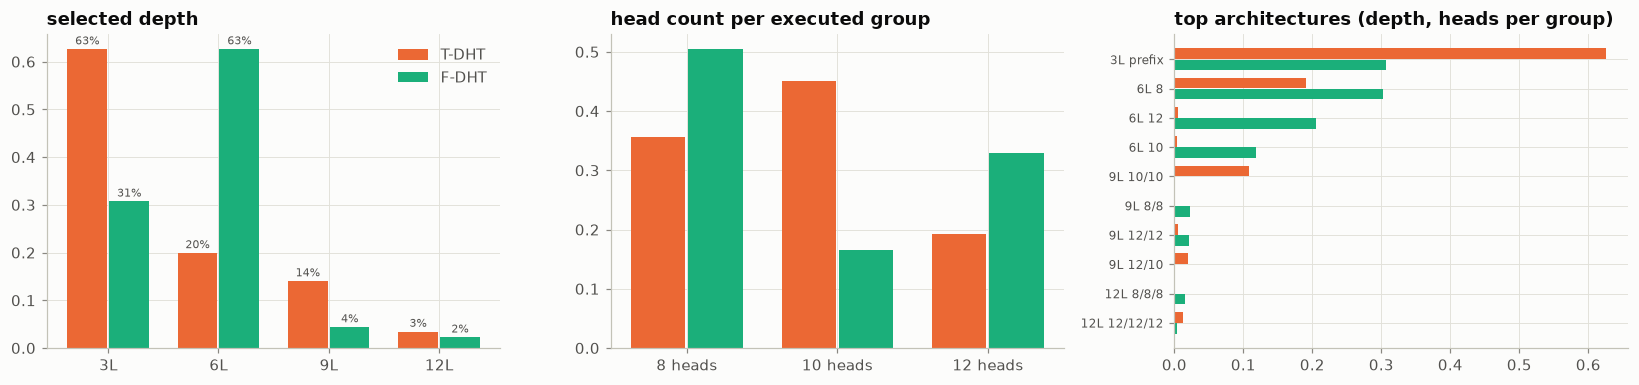

In [9]:
t, f = preds["T-DHT"], preds["F-DHT"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
ax = axes[0]
x = np.arange(4)
for i, (m, fr) in enumerate([("T-DHT", t), ("F-DHT", f)]):
    share = fr.total_depth.value_counts(normalize=True).reindex([3, 6, 9, 12], fill_value=0)
    ax.bar(x + (i - 0.5) * 0.38, share.values, 0.36, color=u.MODEL_COLORS[m], label=m)
    for xi, v in zip(x, share.values):
        ax.text(xi + (i - 0.5) * 0.38, v + 0.01, f"{v:.0%}", ha="center", fontsize=7, color=u.INK2)
ax.set_xticks(x, ["3L", "6L", "9L", "12L"])
ax.set_title("selected depth")
ax.legend()
ax = axes[1]
for i, (m, fr) in enumerate([("T-DHT", t), ("F-DHT", f)]):
    cnt = Counter(c for cs in fr.group_counts for c in cs)
    tot = sum(cnt.values())
    vals = [cnt[k] / tot for k in [8, 10, 12]]
    ax.bar(np.arange(3) + (i - 0.5) * 0.38, vals, 0.36, color=u.MODEL_COLORS[m], label=m)
ax.set_xticks(range(3), ["8 heads", "10 heads", "12 heads"])
ax.set_title("head count per executed group")
ax = axes[2]


def pat(fr):
    return fr.apply(
        lambda r: (
            f"{r.total_depth}L "
            + ("/".join(map(str, r.group_counts)) if r.group_counts else "prefix")
        ),
        axis=1,
    )


top = pd.concat(
    {"T-DHT": pat(t).value_counts(normalize=True), "F-DHT": pat(f).value_counts(normalize=True)},
    axis=1,
).fillna(0)
top = top.loc[top.max(axis=1).sort_values(ascending=False).index[:10]]
y = np.arange(len(top))
for i, m in enumerate(["T-DHT", "F-DHT"]):
    ax.barh(y + (i - 0.5) * 0.38, top[m], 0.36, color=u.MODEL_COLORS[m], label=m)
ax.set_yticks(y, top.index, fontsize=8)
ax.invert_yaxis()
ax.set_title("top architectures (depth, heads per group)")
fig.tight_layout()

In [10]:
depth_agreement = pd.crosstab(
    t.total_depth.rename("T-DHT depth"), f.total_depth.rename("F-DHT depth")
)
display(depth_agreement)
print(
    f"Same depth chosen for {np.mean(t.total_depth.values == f.total_depth.values):.1%} of test samples"
)
print("Mean compute by class:")
cls = pd.Categorical.from_codes(t.label, u.AG_NEWS_CLASSES)
display(
    pd.DataFrame(
        {m: preds[m].groupby(cls, observed=True).flops.mean() for m in ["T-DHT", "F-DHT"]}
    ).style.format("{:.3f}x")
)

F-DHT depth,3,6,9,12
T-DHT depth,,,,
3,2287,2362,83,27
6,9,1405,67,33
9,36,907,92,31
12,3,86,92,80


Same depth chosen for 50.8% of test samples
Mean compute by class:


,T-DHT,F-DHT
World,0.256x,0.269x
Sports,0.252x,0.469x
Business,0.501x,0.530x
Sci/Tech,0.534x,0.460x


**Two different ways to spend the same budget.**

- **T-DHT is bimodal.** 63% of samples stop at 3 layers; the rest are spread over 6/9/12 layers.
  Because it chooses head counts per group, its deep paths mostly keep 10–12 heads.
- **F-DHT is centred.** 63% of samples take **6 layers**, and 8 heads is its most common count. It
  has to commit to one head count for every group from the layer-3 context, and a thin
  6-layer path is a cheap hedge.
- **The two modes agree on 97.7% of predictions but only 50.8% of depths.** Most disagreements are
  T-DHT's 3-layer exits that F-DHT sends to 6 layers (2,362 samples). The architectures differ far
  more than the answers do.
- **By class:** F-DHT spends more on Sports (0.47x vs 0.25x) and less on Sci/Tech (0.46x vs 0.53x).
  Tree search's "Sports is easy, stop at 3" pattern is not something integrated search learned.

## 6. Same samples, both policies — correctness and examples

In [11]:
fx = preds["Fixed BERT"]
outcome = pd.DataFrame({"fixed": fx.correct, "T-DHT": t.correct, "F-DHT": f.correct})
pattern = outcome.apply(lambda r: "".join("✓" if v else "✗" for v in r), axis=1)
table = pattern.value_counts().rename_axis("fixed / T-DHT / F-DHT").to_frame("samples")
display(table)
print(f"T-DHT vs F-DHT prediction agreement: {(t.prediction == f.prediction).mean():.2%}")

,samples
fixed / T-DHT / F-DHT,
✓✓✓,6991
✗✗✗,256
✓✗✗,114
✗✓✓,74
✓✓✗,61
✓✗✓,47
✗✗✓,39
✗✓✗,18


T-DHT vs F-DHT prediction agreement: 97.67%


In [12]:
def arch(r):
    return f"{r.total_depth:>2}L " + (
        "/".join(map(str, r.group_counts)) + "H" if r.group_counts else "(prefix only)"
    )


def examples(mask, title, n=4, seed=1):
    idx = outcome[mask].sample(min(n, int(mask.sum())), random_state=seed).index
    print(f"\n▶ {title}  ({int(mask.sum())} samples)")
    for i in idx:
        txt = t.text[i].replace("\\", " ")
        print(
            f"  true={u.AG_NEWS_CLASSES[t.label[i]]:<8}  T-DHT→{u.AG_NEWS_CLASSES[t.prediction[i]]:<8} [{arch(t.loc[i]):<16}]  "
            f"F-DHT→{u.AG_NEWS_CLASSES[f.prediction[i]]:<8} [{arch(f.loc[i]):<16}]"
        )
        print(f"     “{txt[:160]}{'…' if len(txt) > 160 else ''}”")


examples(outcome["T-DHT"] & ~outcome["F-DHT"], "Tree right, integrated wrong")
examples(~outcome["T-DHT"] & outcome["F-DHT"], "Integrated right, tree wrong")
examples(
    (t.total_depth - f.total_depth).abs().eq(9),
    "Same sample, opposite ends: one uses 3 layers, the other 12",
)


▶ Tree right, integrated wrong  (79 samples)
  true=Sports    T-DHT→Sports   [ 3L (prefix only)]  F-DHT→Sci/Tech [ 3L (prefix only)]
     “Arrowhead: It still is pointing the way In comparison to its contemporaries it could be termed a modern marvel, an example of how to do things right when everyo…”
  true=World     T-DHT→World    [ 3L (prefix only)]  F-DHT→Sci/Tech [ 3L (prefix only)]
     “Men, Women More Different Than Thought CHICAGO - Beyond the tired cliches and sperm-and-egg basics taught in grade school science class, researchers are discove…”
  true=Business  T-DHT→Business [ 6L 8H          ]  F-DHT→Sci/Tech [ 6L 8H          ]
     “SUSAN TOMPOR: Stores turn paper into e-checks I picked up my 6-year-old son from school last week, and we drove to Wal-Mart to see the future for paper checks. …”
  true=Sci/Tech  T-DHT→Sci/Tech [ 3L (prefix only)]  F-DHT→Business [ 9L 12/12H      ]
     “Supreme Court Hears Wine Sales Case Winemakers who want to ship directly to consumers across

### The same sentence, three networks

Each figure uses the same visual key as notebook 01, Part 3:

- **Left:** class probabilities from full BERT, T-DHT and F-DHT.
- **Right:** 12 layers × 12 heads per model.
  - **Filled** squares were computed.
  - **White** squares are heads that were dropped.
  - **Gray** rows are layers that never ran.
  - The dotted line marks the always-on prefix.

Tree search can vary the head count group by group (e.g. 12 → 10 → 12); integrated search keeps one
count for every group.

**Tree right, integrated wrong** — test #524, true class **World**  
“British Minister Sees 'Show Camp' in Sudan (Reuters) Reuters - Two rows of well-spaced mattresses with brightly colored covers are laid out in a straw hut, and the smiling nurse in surgical gloves gives an injection to a”

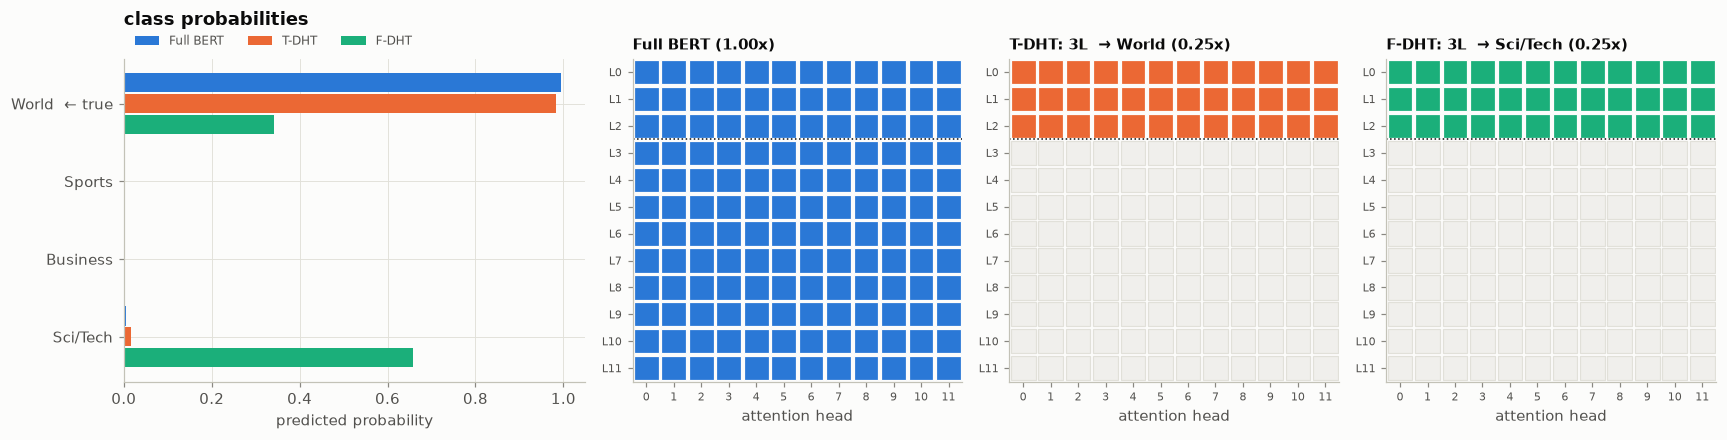

**Integrated right, tree wrong** — test #689, true class **World**  
“Vote 2004 - a guide to the primary Get ready for the primary with the Herald-Tribunes special news section profiling all the federal, state and local candidates in races in Tuesdays election.”

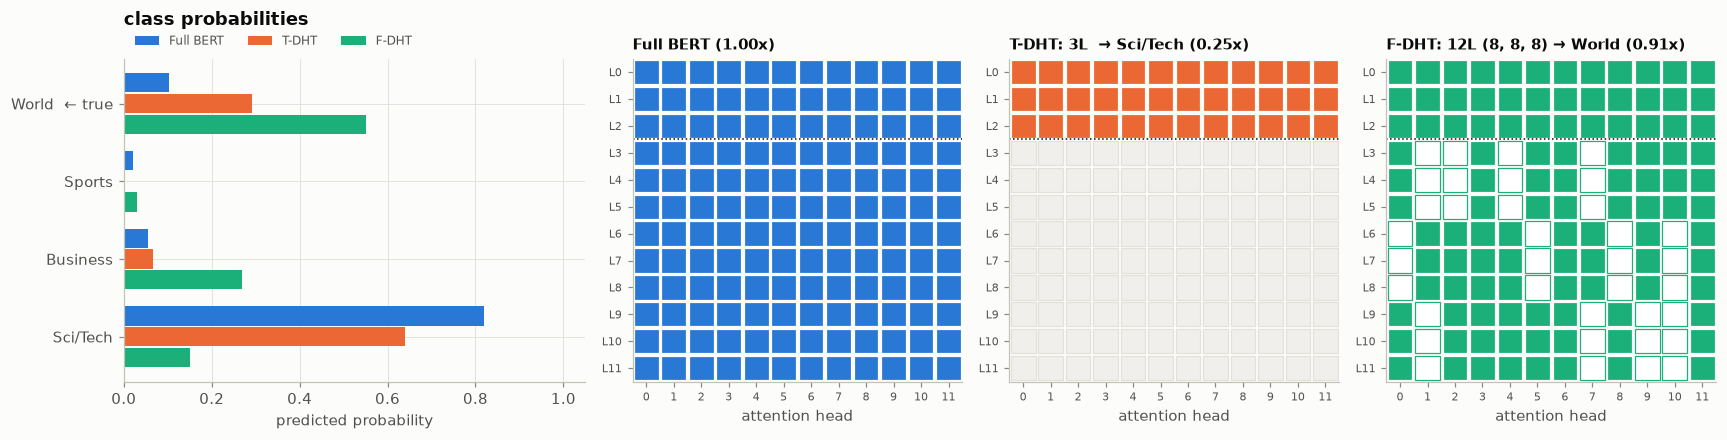

**Both right, opposite compute (3 vs 12 layers)** — test #5779, true class **Sci/Tech**  
“Wonkette: Blogs force quick action from major media Plus: Row brewing over peer-to-peer ads. News.com Extra”

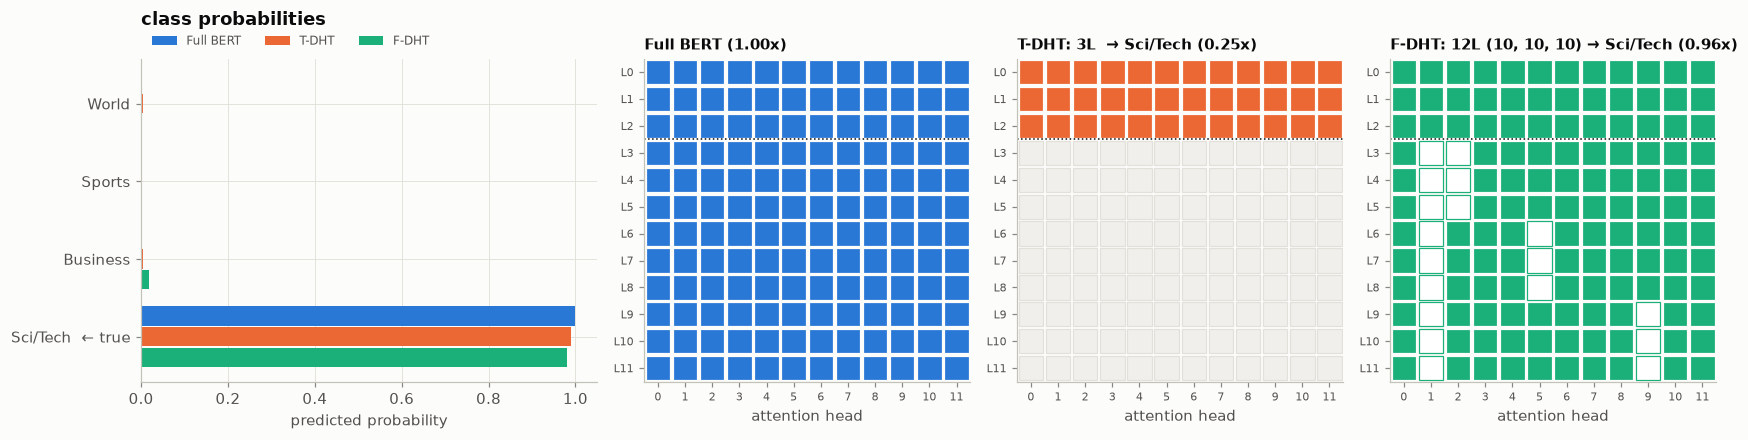

**Both right, both thin heads** — test #3830, true class **Sci/Tech**  
“Intel Cancels Revamped Chip The Intel Corporation said on Thursday that it was canceling its plans to market a faster version of its Pentium 4 chip for personal computers to focus on products with  quot;more bang for the”

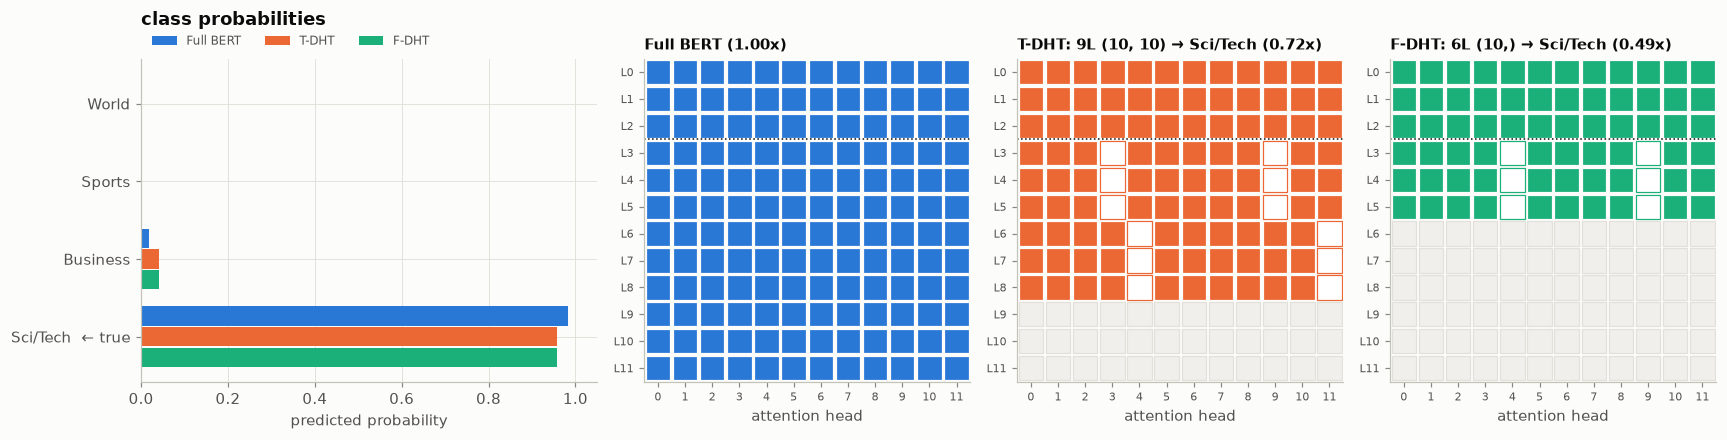

In [13]:
import sample_anatomy as sa

cases = {
    "Tree right, integrated wrong": outcome.index[outcome["T-DHT"] & ~outcome["F-DHT"]],
    "Integrated right, tree wrong": outcome.index[~outcome["T-DHT"] & outcome["F-DHT"]],
    "Both right, opposite compute (3 vs 12 layers)": outcome.index[
        outcome["T-DHT"] & outcome["F-DHT"] & (t.total_depth - f.total_depth).abs().eq(9)
    ],
    "Both right, both thin heads": outcome.index[
        outcome["T-DHT"]
        & outcome["F-DHT"]
        & t.group_counts.map(lambda c: len(c) > 0 and min(c) < 12)
        & f.group_counts.map(lambda c: len(c) > 0 and min(c) < 12)
    ],
}
pick_rng = np.random.default_rng(11)
for title, candidates in cases.items():
    if len(candidates) == 0:
        continue
    i = int(pick_rng.choice(candidates))
    display(
        Markdown(
            f"**{title}** — test #{i}, true class **{u.AG_NEWS_CLASSES[t.label[i]]}**  \n“{t.text[i].replace(chr(92), ' ')[:220]}”"
        )
    )
    sa.compare_figure(t.text[i], int(t.label[i]))
    plt.show()

### Live decision traces, side by side

Both validation-selected checkpoints are loaded on CPU. `DHTController.explain()` then prints the
frozen scores behind every choice for a few test samples and some made-up headlines. The key
contrast:

- **T-DHT** scores **4 depths**, then scores counts again *at each group*.
- **F-DHT** scores **all 10 (depth, heads) pairs once**.

In [14]:
from dht.models.pretrained import build_model
from dht.training.trainer import restore_controller

torch.set_num_threads(4)
loaded = {}
for m in ["T-DHT", "F-DHT"]:
    model = build_model(cfgs[m], initialize=False)
    model.load_state_dict(states[m]["model"])
    model.eval()
    loaded[m] = (model, restore_controller(cfgs[m], states[m]))
tok = u.tokenizer()
tok.enable_truncation(max_length=128)
tok.enable_padding(length=128, pad_id=0, pad_token="[PAD]")


@torch.no_grad()
def both(text, label=None):
    ids = torch.tensor([tok.encode(text).ids])
    print(
        f"“{text[:140]}”" + (f"  [true: {u.AG_NEWS_CLASSES[label]}]" if label is not None else "")
    )
    for m, (model, c) in loaded.items():
        logits, tr = c.explain(model, ids)
        p = logits.softmax(-1)[0]
        counts = tuple(g["head_count"] for g in tr["groups"])
        best = sorted(zip(tr["route_scores"], tr["route_actions"]), reverse=True)[:3]
        fmt = (lambda a: f"{a}L") if m == "T-DHT" else (lambda a: f"{a[0]}L{a[1]}H")
        print(
            f"  {m}: {u.AG_NEWS_CLASSES[int(p.argmax())]:<8} p={float(p.max()):.2f} | {tr['total_depth']}L, heads/group={counts or '—'}, "
            f"compute={u.relative_matmul_flops(tr['total_depth'], counts):.2f}x"
        )
        print("        top route arms: " + ", ".join(f"{fmt(a)}:{s:+.1f}" for s, a in best))
        for g in tr["groups"]:
            cs = (
                ""
                if g["count_scores"] is None
                else "count UCB "
                + ", ".join(f"{k}H:{s:+.1f}" for k, s in zip(c.counts, g["count_scores"]))
                + " → "
            )
            drop = sorted(set(range(12)) - set(g["selected_heads"]))
            print(
                f"        layers {g['start_layer']}–{g['start_layer'] + 2}: {cs}{g['head_count']} heads, dropped {drop}"
            )
    print()


for i in [0, 1, 17, 42]:
    both(raw_test.text.iloc[i], int(raw_test.label.iloc[i]))
for text in [
    "Yankees rally in the ninth to beat Red Sox 5-4",
    "Apple shares jump after record iPhone sales beat Wall Street forecasts",
    "Microsoft to cut 5,000 jobs as cloud growth slows",
]:
    both(text)

“Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken paren”  [true: Business]
  T-DHT: Business p=0.98 | 12L, heads/group=(8, 12, 12), compute=0.97x
        top route arms: 12L:+0.5, 9L:-0.5, 6L:-1.5
        layers 3–5: count UCB 8H:+9.2, 10H:-2.0, 12H:+4.8 → 8 heads, dropped [1, 3, 8, 9]
        layers 6–8: count UCB 8H:-3.4, 10H:-2.6, 12H:+3.0 → 12 heads, dropped []
        layers 9–11: count UCB 8H:-15.5, 10H:-19.8, 12H:+5.3 → 12 heads, dropped []
  F-DHT: Business p=0.95 | 6L, heads/group=(10,), compute=0.49x
        top route arms: 6L10H:+1.8, 3L12H:+1.6, 12L10H:+0.4
        layers 3–5: 10 heads, dropped [1, 2]

“The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com) SPACE.com - TORONTO, Canada -- A second\team of rocke”  [true: Sci/Tech]
  T-DHT: Sci/Tech p=1.00 | 3L, heads/group=—, compute=0.25x
        top route arms: 3L:+29.6, 9L:+14.7, 12L:-0.1
  F-DHT: Sci/Tech 

  T-DHT: World    p=0.99 | 3L, heads/group=—, compute=0.25x
        top route arms: 3L:+40.3, 9L:+7.4, 12L:-0.0
  F-DHT: World    p=0.64 | 3L, heads/group=—, compute=0.25x
        top route arms: 3L12H:+15.6, 6L8H:+10.8, 6L10H:+4.7

“Apple shares jump after record iPhone sales beat Wall Street forecasts”
  T-DHT: Sci/Tech p=0.79 | 9L, heads/group=(12, 12), compute=0.75x
        top route arms: 9L:+2.7, 12L:+0.1, 3L:-2.5
        layers 3–5: count UCB 8H:-29.3, 10H:-0.4, 12H:+4.9 → 12 heads, dropped []
        layers 6–8: count UCB 8H:-35.0, 10H:+0.3, 12H:+2.6 → 12 heads, dropped []
  F-DHT: Sci/Tech p=0.87 | 6L, heads/group=(10,), compute=0.49x
        top route arms: 6L10H:+3.1, 9L8H:+1.1, 12L10H:+0.5
        layers 3–5: 10 heads, dropped [4, 9]

“Microsoft to cut 5,000 jobs as cloud growth slows”
  T-DHT: Sci/Tech p=0.88 | 12L, heads/group=(12, 12, 12), compute=1.00x
        top route arms: 12L:+0.3, 9L:-2.3, 3L:-3.7
        layers 3–5: count UCB 8H:-14.7, 10H:-7.4, 12H:+4.1 → 12 head

## 7. Which heads get dropped?

The TS head-selection frequency per dynamic group shows whether each mode learns a *stable* notion of
unimportant heads (the paper's §7.4 claim) and whether the two modes agree on them.

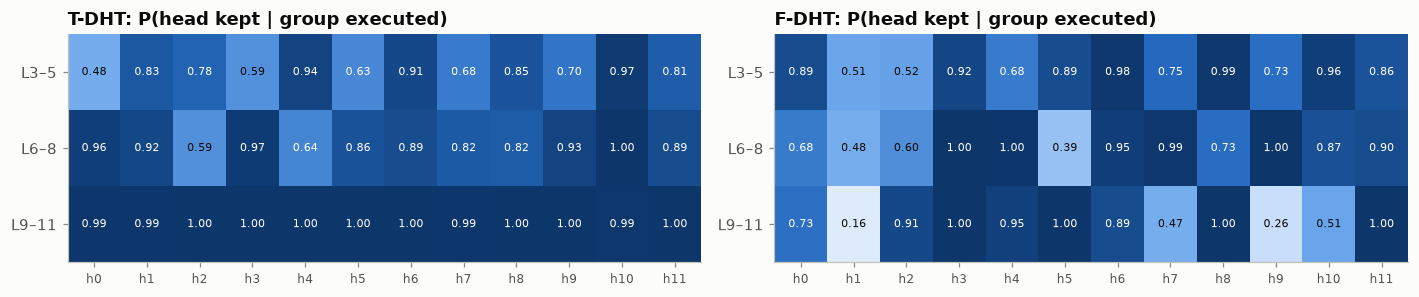

In [15]:
from matplotlib.colors import LinearSegmentedColormap

fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
BLUES = LinearSegmentedColormap.from_list(
    "b", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"]
)
for ax, m in zip(axes, ["T-DHT", "F-DHT"]):
    fr = preds[m]
    mat = np.full((3, 12), np.nan)
    for g in range(3):
        sub = [hs[g] for hs in fr.group_heads if len(hs) > g]
        if sub:
            cnt = Counter(h for hs in sub for h in hs)
            mat[g] = [cnt[h] / len(sub) for h in range(12)]
    im = ax.imshow(mat, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
    ax.grid(False)
    for g in range(3):
        for h in range(12):
            if not np.isnan(mat[g, h]):
                ax.text(
                    h,
                    g,
                    f"{mat[g, h]:.2f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="white" if mat[g, h] > 0.6 else u.INK,
                )
    ax.set_xticks(range(12), [f"h{h}" for h in range(12)], fontsize=8)
    ax.set_yticks(range(3), ["L3–5", "L6–8", "L9–11"])
    ax.set_title(f"{m}: P(head kept | group executed)")
fig.tight_layout()

- **T-DHT** almost never thins its **last** group (layers 9–11 keep ~all heads). Its per-group
  count bandit learned that late layers want full width. Its head dropping happens early (layers
  3–5, e.g. heads 0 and 3).
- **F-DHT** must use the same count everywhere, so it thins *every* group. In layers 9–11 it
  consistently drops **heads 1 and 9** (kept only 16% / 26% of the time).
- The two modes do **not** agree on which heads are unimportant. The paper's §7.4 claim that "some
  heads are less contributive" holds *within* each run, but the specific heads depend on the search
  mode and training trajectory. They are not fixed properties of BERT.

## 8. How the policies evolved during training

This is the paper's Fig. 2 analogue for both modes: the depth-selection share over the three
training epochs (bins of 4,000 trained samples).

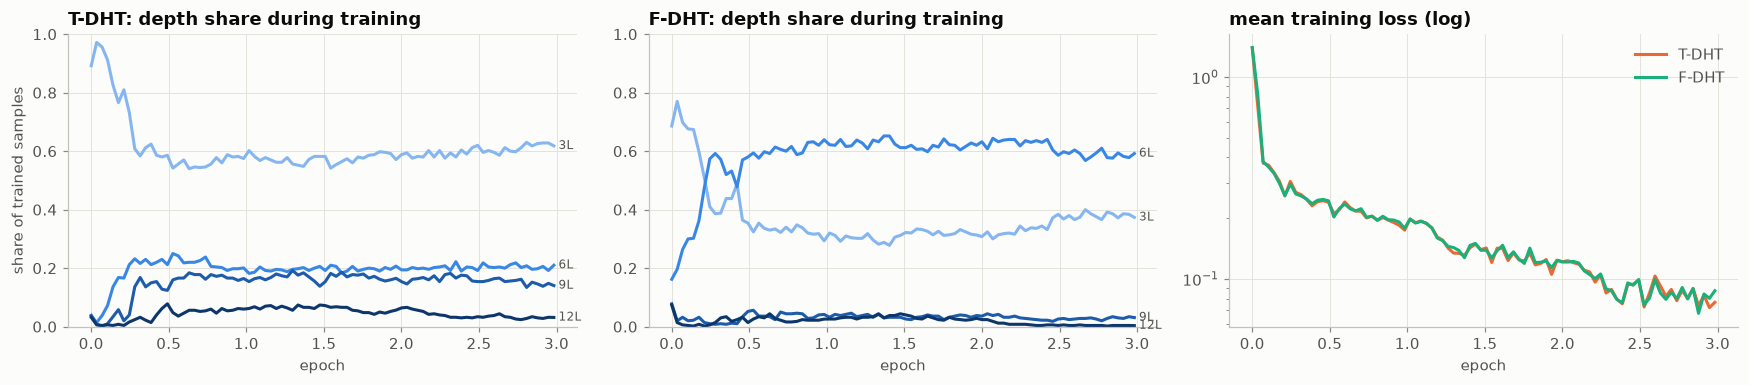

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
sel = {m: u.training_selections(m, every=4000) for m in ["T-DHT", "F-DHT"]}
for ax, m in zip(axes[:2], ["T-DHT", "F-DHT"]):
    share = pd.crosstab(sel[m].bin, sel[m].depth, normalize="index")
    xs = share.index * 4000 / 114000
    for d in share.columns:
        ax.plot(xs, share[d], color=u.DEPTH_COLORS[d], label=f"{d}L")
        ax.text(xs[-1] + 0.03, share[d].iloc[-1], f"{d}L", fontsize=8, color=u.INK2, va="center")
    ax.set_ylim(0, 1)
    ax.set_xlabel("epoch")
    ax.set_title(f"{m}: depth share during training")
axes[0].set_ylabel("share of trained samples")
ax = axes[2]
for m in ["T-DHT", "F-DHT"]:
    loss = sel[m].groupby("bin").loss.mean()
    ax.plot(loss.index * 4000 / 114000, loss, color=u.MODEL_COLORS[m], label=m)
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_title("mean training loss (log)")
ax.legend()
fig.tight_layout()

In [17]:
pair_share = sel["F-DHT"].assign(
    pair=lambda d: (
        d.depth.astype(str) + "L" + d.counts.map(lambda c: str(c[0]) + "H" if c else "12H")
    )
)
ps = pd.crosstab(
    pd.cut(
        pair_share.position,
        [0, 38000, 114000, 228000, 342000],
        right=False,
        labels=["epoch 1 (first third)", "epoch 1 (rest)", "epoch 2", "epoch 3"],
    ),
    pair_share.pair,
    normalize="index",
)
ps[
    sorted(ps.columns, key=lambda s: (int(s.split("L")[0]), int(s.split("L")[1][:-1])))
].style.format("{:.1%}").background_gradient(cmap=BLUES, axis=None)

pair,3L12H,6L8H,6L10H,6L12H,9L8H,9L10H,9L12H,12L8H,12L10H,12L12H
position,,,,,,,,,,
epoch 1 (first third),59.0%,24.5%,2.9%,9.5%,0.4%,0.9%,1.2%,0.4%,0.7%,0.4%
epoch 1 (rest),35.4%,27.6%,11.5%,19.6%,2.1%,0.3%,1.1%,1.0%,0.9%,0.6%
epoch 2,31.1%,28.5%,13.8%,20.0%,2.1%,0.3%,1.1%,1.4%,0.7%,0.9%
epoch 3,35.4%,29.2%,10.0%,21.7%,2.3%,0.1%,0.5%,0.4%,0.2%,0.1%


**Both modes reverse the paper's reported trend.** The paper (§6.3, §7.4) says the 3-layer
option becomes *more* dominant over training, and for F-IDHT that "3 layers is selected mostly…,
6 layers is secondary". In our runs:

- **T-DHT:** 3 layers starts at ~90–97% and falls to a stable ~60%.
- **F-DHT:** 3 layers starts at ~70–77% and falls to ~30–40% by mid-epoch 1, while **6 layers rises
  to ~60%** and stays there.

The early preference for the cheapest action is consistent with the ratio reward: before the network
has learned, loss is similar everywhere and the cost factor dominates. Training loss is
indistinguishable between the modes, so the paper's stability claim holds for both.

## 9. Wall-clock speed: making the FLOP savings real (D017)

The original implementation executed DHT **one sample at a time**, both in training and inference.
Fewer FLOPs therefore did not mean less time: the full T-DHT run trained 1.58× slower and inferred
2.55× slower than fixed BERT.

The batched engine (`[dht] execution = "batched"`) runs the *same* algorithm with the same decisions
and random stream, as the equivalence tests enforce, but lays it out for parallel hardware:

- one prefix pass per batch
- per-sample head slices inside one `torch.bmm`
- one CPU transfer per group
- vectorized TS posterior updates
- at inference, a shared routing/execution prefix

Measurements below are from `scripts/benchmark_inference.py` and `scripts/benchmark_training.py`,
run on an otherwise idle Apple M2 Max (MPS).

In [18]:
inf = json.loads((u.ANALYSIS / "inference_benchmark.json").read_text())
rows = pd.DataFrame(inf["results"])
rows["model"] = (
    rows.model.str.replace(r"tree:.*", "T-DHT", regex=True)
    .str.replace(r"integrated:.*", "F-DHT", regex=True)
    .replace({"fixed": "Fixed BERT"})
)
rows["variant"] = rows.model + rows.execution.fillna("").map(
    lambda e: f" ({e.replace('_', '-')})" if e else ""
)
pivot = rows.pivot_table(index="variant", columns="batch_size", values="samples_per_second")
fixed_speed = rows.query("model == 'Fixed BERT'").set_index("batch_size").samples_per_second
rel = pivot / fixed_speed
display(pd.concat({"samples/s": pivot, "× fixed BERT": rel}, axis=1).style.format("{:.2f}"))
print("architecture agreement with the per-sample reference (512 validation samples):")
display(
    rows.dropna(subset=["architecture_agreement"])
    .pivot_table(index="variant", columns="batch_size", values="architecture_agreement")
    .style.format("{:.1%}")
)
full = json.loads((u.ANALYSIS / "device_pooling_validation_agreement.json").read_text())
display(
    pd.DataFrame(full)
    .T.rename(index=lambda r: "T-DHT" if "tree" in r else "F-DHT")
    .style.format(precision=5)
    .set_caption("GPU pooling vs exact float64 pooling on all 6,000 validation samples")
)

architecture agreement with the per-sample reference (512 validation samples):


batch_size,8,32
variant,,
F-DHT (batched),100.0%,100.0%
F-DHT (batched-device-pooling),100.0%,100.0%
F-DHT (per-sample),100.0%,100.0%
T-DHT (batched),100.0%,100.0%
T-DHT (batched-device-pooling),100.0%,100.0%
T-DHT (per-sample),100.0%,100.0%


,architecture_agreement,differing,prediction_agreement,macro_f1_exact,macro_f1_device,recorded_validation_macro_f1
T-DHT,1.00000,0.00000,1.00000,0.94383,0.94383,0.94383
F-DHT,1.00000,0.00000,1.00000,0.94523,0.94523,0.94523


,samples/s,× fixed BERT,routing ms/sample,forward_including_head_policy ms/sample,backward_optimizer ms/sample,controller_update ms/sample
variant,,,,,,
Fixed BERT,50.27,1.00,—,—,—,—
T-DHT (per-sample),29.76,0.59,7.92,10.64,13.67,1.28
T-DHT (batched),75.36,1.50,2.70,3.87,6.36,0.28
T-DHT (batched + GPU pooling),80.36,1.60,2.02,3.57,6.48,0.31
F-DHT (per-sample),21.59,0.44,9.02,14.88,19.16,3.15
F-DHT (batched),42.31,0.87,3.36,7.76,11.43,1.00
F-DHT (batched + GPU pooling),46.92,0.96,2.10,7.08,11.15,0.89


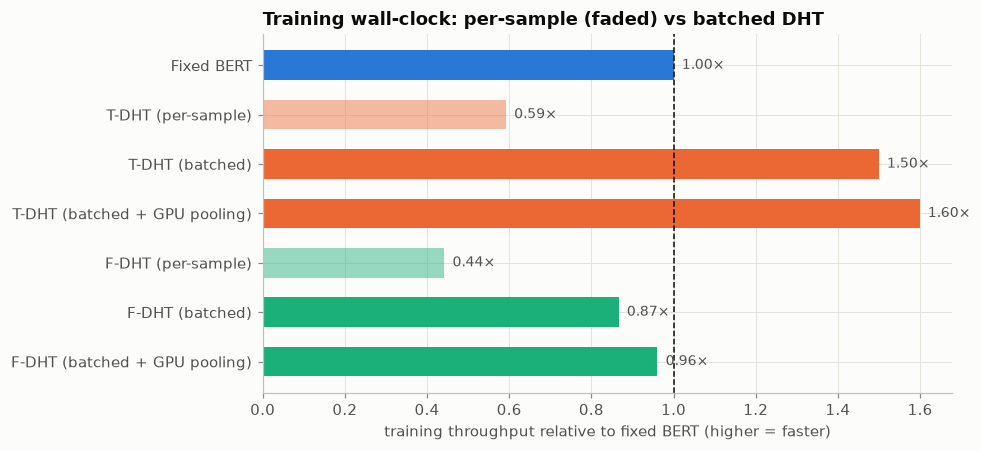

In [19]:
trains = {
    m: json.loads((u.ANALYSIS / f"training_benchmark_{k}.json").read_text())
    for m, k in [("T-DHT", "tree"), ("F-DHT", "fdht")]
}
rows = []
for m, b in trains.items():
    rows.append(
        {
            "variant": "Fixed BERT",
            "samples/s": b["fixed_bert"]["samples_per_second"],
            "bench": m,
            "× fixed BERT": 1.0,
        }
    )
    for k, label in [
        ("dht_per_sample", f"{m} (per-sample)"),
        ("dht_batched", f"{m} (batched)"),
        ("dht_batched_device_pooling", f"{m} (batched + GPU pooling)"),
    ]:
        r = b[k]
        rows.append(
            {
                "variant": label,
                "samples/s": r["samples_per_second"],
                "bench": m,
                "× fixed BERT": r["speed_vs_fixed"],
                **{
                    f"{p.replace('_seconds', '')} ms/sample": v
                    for p, v in r["ms_per_sample"].items()
                },
            }
        )
tb = pd.DataFrame(rows).drop_duplicates("variant", keep="first").set_index("variant")
# Each DHT row is divided by the fixed-BERT run of its OWN benchmark session.
display(tb.drop(columns="bench").style.format(precision=2, na_rep="—"))

fig, ax = plt.subplots(figsize=(9, 4.2))
order = [
    "Fixed BERT",
    "T-DHT (per-sample)",
    "T-DHT (batched)",
    "T-DHT (batched + GPU pooling)",
    "F-DHT (per-sample)",
    "F-DHT (batched)",
    "F-DHT (batched + GPU pooling)",
]
colors = (
    [u.MODEL_COLORS["Fixed BERT"]] + [u.MODEL_COLORS["T-DHT"]] * 3 + [u.MODEL_COLORS["F-DHT"]] * 3
)
vals = tb.loc[order, "× fixed BERT"]
bars = ax.barh(order, vals, color=colors, height=0.6)
for bar, name in zip(bars, order):
    if "per-sample" in name:
        bar.set_alpha(0.45)
for y, v in enumerate(vals):
    ax.text(v + 0.02, y, f"{v:.2f}×", va="center", fontsize=9, color=u.INK2)
ax.axvline(1, color=u.INK, lw=1, ls="--")
ax.invert_yaxis()
ax.set_xlabel("training throughput relative to fixed BERT (higher = faster)")
ax.set_title("Training wall-clock: per-sample (faded) vs batched DHT")
fig.tight_layout()

**What changed and what didn't.** Four engines are compared: per-sample (original), batched with
exact float64 CPU pooling (D017), batched with GPU pooling (D018), and fixed BERT.

- **Training (batch 8, MPS):**
  - T-DHT: 0.59× → 1.50× → **1.60× fixed BERT**.
  - F-DHT: 0.44× → 0.87× → **0.96×**.
  - The backward pass now dominates DHT's step time. Head-sliced weight gradients are less efficient
    per FLOP than one dense matmul, and F-DHT's early-training policy (0.54x FLOPs in the benchmark
    window vs 0.33x for T-DHT) does more of that work.
- **Inference (batch 32):**
  - T-DHT: 0.26× → 0.91× → **~1.12× fixed BERT**; F-DHT: 0.24× → 0.87× → **~1.11×**.
  - Before GPU pooling, ~23% of batched inference time was copying hidden states to the CPU and
    pooling them in float64. D018 pools on the GPU with one prefix sum and copies only ~84 numbers
    per sample.
  - Batch 8 gains less (1.00–1.06×): per-batch fixed costs matter more.
- **What stays on the CPU:** UCB/TS statistics and their float64 updates. MPS has no float64, the UCB
  matrices accumulate ~10^5 updates, and these operations take microseconds per batch. Moving them
  would add numerical risk for no measurable gain.
- **Correctness:**
  - The float64 batched engine is bit-identical to the per-sample path (tests; logit diff 0.0).
  - GPU pooling is float32, so it is *not* guaranteed identical. Measured on all 6,000 validation
    samples it chose the same architecture and prediction for **every** sample, with identical
    macro F1.
  - Run-to-run timing varies by roughly ±10%; treat ratios, not decimals, as the result.

## 10. Conclusions

1. **Conceptually**, integrated search is a flat contextual bandit over a curated (depth, heads)
   menu with one joint reward. Tree search is a hierarchy of bandits: it chooses depth first, then a
   head count per 3-layer group, informed by deeper representations.
2. **In code**, the difference is small and local. It comes down to four branches in
   `DHTController`:
   - which bandits exist
   - what stage 1 selects
   - who picks the head count
   - how the reward's cost term is formed

   Everything else is shared: prefix, queues, TS, calibration and the batched engine.
3. **On individual samples**, the modes agree on 97.7% of answers but only half of depths. Tree
   search is bimodal (3 layers or deep); integrated search is centred on thin 6-layer paths. Each
   wins roughly 80 samples the other loses.
4. **Final results**:
   - test macro F1: F-DHT .9409, T-DHT .9400 (a tie on one seed), fixed BERT .9490
   - task FLOPs: 0.43x and 0.39x

   Neither reproduces the paper's "DHT ≈ BERT" accuracy against our stronger baseline, and the
   paper's T-vs-F compute ordering and 3-layer dynamics are not reproduced.
5. **Wall-clock**: batched execution plus GPU context pooling makes T-DHT train 1.60× faster than
   fixed BERT. Both DHT modes infer ~1.1× faster than fixed BERT on the GPU at batch 32, with every
   validation decision unchanged.

**Next:** ≥3 seeds per mode, the S-DHT pair list, a cheaper head-sliced backward pass, and the reward/RL
extensions in `docs/research/next_topics.md`.